# LM23 Lab — Linear Regression

Companion notebook to **From Calculus to Kelly, LM23**. It repairs the sector closes, rebuilds the module's exhibits and computational examples, solves the computational practice problems, and ends with an extension exercise.

| Part | Rebuilds |
|:--|:--|
| 1 | Data: the repair cell, U28 and Electronic, $T$, $A$, the halves and the lag rule; TR23 on U28's dates; LM2's pairs |
| 2 | OLS by hand: Example 1, Exhibit 1, Example 2, and statsmodels with every option |
| 3 | Intervals and hat values: Exhibit 2, Example 3 |
| 4 | White's standard errors: Example 4 on LM18's paths, the 28 ratios, LM16's slope |
| 5 | Overlapping sums and Newey–West: Exhibit 3, Example 5, the iid factors, Exhibit 4 |
| 6 | Market model and hedging: (23.8), Exhibit 5, Exhibit 6, Example 6, Example 7 |
| 7 | Twenty-eight alphas: Exhibit 7, Bonferroni, Holm and Benjamini–Hochberg, Example 8 (experiment 1) |
| 8 | A factor named in advance: Exhibit 8, Example 9, the variance inflation factors |
| 9 | Practice problems 8, 11 and 12, and an extension: a walk-forward hedge |

**Environment.** From the repository root, `uv sync` installs the locked Python environment (`uv.lock`). Open this notebook with the `.venv` kernel, or run `uv run --with jupyterlab jupyter lab`.

**Data.** The notebook reads FinMind files that you download once with your own token. From the repository root, run `uv run python data/fetch_finmind.py`, then `uv run python data/make_lab_data.py`. FinMind's licence does not allow the book to redistribute the data. After that, the notebook runs offline.

`data/` then holds `sectors_close_raw.csv` (the closes FinMind's `TaiwanStockPrice` serves for TAIEX and the 30 TWSE sector indices, one column per series), `sectors_close_repairs.csv` (the 561 closes that FinMind copied from another date or series, each with its official 13:30:00 value from `TaiwanStockEvery5SecondsIndex`), `taiex_tr.csv` (the TAIEX total-return index, `TaiwanStockTotalReturnIndex`), and `0050_daily_raw.csv`, `0050_dividends.csv` and `00631L_daily_raw.csv` (LM2's funds). The notebook reads nothing outside `data/`.

**Conventions (as in the module).** U28: daily simple price returns (no dividends) of the 28 leaf TWSE sector indices and the TAIEX price index between consecutive TAIEX-calendar dates, closes 2008-12-01 to 2026-10-08, $T=4{,}382$ returns. OLS with an intercept; $s_\varepsilon^2=\text{RSS}/(T-d)$; classical standard errors $s_\varepsilon^2(X^{\top}X)^{-1}$; White's HC0 with no degrees-of-freedom factor; Newey–West with Bartlett weights $1-k/(\ell+1)$, no small-sample correction and the lag $\ell=\lfloor4(T/100)^{2/9}\rfloor$ unless stated. Descriptive means, standard deviations and correlations divide by $T$ (`ddof=0`). t-stats and p-values use the normal reference, two-sided, except LM12's four points ($t_2$). Quantiles are $\hat F^{-1}(u)$ (`method="inverted_cdf"`). Every count against a threshold uses the guard `1e-12`. Fits and tests are in-sample; halves, years and rolling windows are stability checks; the hedges of Example 6 and of the extension are judged out of sample.

In [1]:
from datetime import date
from fractions import Fraction
from math import floor, sqrt
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import polars as pl
import statsmodels.api as sm
from scipy import stats
from statsmodels.stats.multitest import multipletests

DATA = Path("data")
FIRST_CLOSE, LAST_CLOSE = "2008-12-01", "2026-10-08"
AGGREGATES = ["Electronic", "ChemicalBiotechnologyMedicalCare"]
EPS = 1e-12
pl.Config.set_tbl_rows(40)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3,
                     "axes.spines.top": False, "axes.spines.right": False})


def nw_lag(n):
    # the book's lag rule: statsmodels' default HAC lag, Newey and West's (1994) pilot lag
    return floor(4 * (n / 100) ** (2 / 9))


def design(*cols):
    return np.column_stack([np.ones(len(cols[0])), *cols])


def long_run(u, lag):
    # sum_t u_t u_t' + sum_{k=1}^{lag} (1 - k/(lag+1)) (G_k + G_k'), G_k = sum_t u_t u_{t-k}'  (Bartlett weights)
    s = u.T @ u
    for k in range(1, lag + 1):
        g = u[k:].T @ u[:-k]
        s = s + (1 - k / (lag + 1)) * (g + g.T)
    return s


def ols(y, z, lag=None):
    # OLS with classical, White (HC0) and Newey-West standard errors; returns a dict
    n, d = z.shape
    zi = np.linalg.inv(z.T @ z)
    b = zi @ (z.T @ y)
    e = y - z @ b
    s2 = e @ e / (n - d)                                  # divisor T - d
    u = z * e[:, None]
    L = nw_lag(n) if lag is None else lag
    yc = y - y.mean()
    return {"b": b, "e": e, "s2": s2, "zi": zi, "lag": L, "n": n,
            "se_c": np.sqrt(s2 * np.diag(zi)),
            "se_w": np.sqrt(np.diag(zi @ (u.T @ u) @ zi)),
            "se_n": np.sqrt(np.diag(zi @ long_run(u, L) @ zi)),
            "r2": 1 - (e @ e) / (yc @ yc)}


def two_sided(t):
    return 2 * stats.norm.sf(abs(t))

## Part 1 — Data

FinMind's `TaiwanStockPrice` serves the sector indices with some rows copied from another date, or from another series on the same date (PITFALLS §3 of the repository). The book replaces each of these closes with the official 13:30:00 value. On FinMind's free plan the 13:30:00 values are not available (`TaiwanStockEvery5SecondsIndex` is a paid dataset), so `close_1330` is empty and the cell **drops** those closes instead: the returns into and out of each dropped date leave the common sample, which then holds 4,307 returns instead of 4,382. Nothing is ever estimated.

In [2]:
raw = pl.read_csv(DATA / "sectors_close_raw.csv", infer_schema_length=None).sort("date")
rep = pl.read_csv(DATA / "sectors_close_repairs.csv", infer_schema_length=None,
                  schema_overrides={"close_1330": pl.Float64})
series = [c for c in raw.columns if c != "date"]
fixed = raw
for sid in rep["id"].unique(maintain_order=True).to_list():
    g = rep.filter(pl.col("id") == pl.lit(sid)).select("date", pl.col("close_1330").alias("_new"),
                                                        pl.lit(True).alias("_listed"))
    fixed = (fixed.join(g, on="date", how="left").sort("date")
                  .with_columns(pl.when(pl.col("_listed")).then(pl.col("_new")).otherwise(pl.col(sid)).alias(sid))
                  .drop("_new", "_listed"))
n_listed, n_replaced = rep.height, int(rep["close_1330"].is_not_null().sum())
FULL_DATA = n_replaced == n_listed
U28 = [c for c in series if c not in ("TAIEX", *AGGREGATES)]
print("Rule: every close listed in sectors_close_repairs.csv is replaced by its 13:30:00 value (close_1330);")
print("      a listed close without that value is dropped (set to missing), never estimated.")
print(f"listed closes {n_listed}: replaced {n_replaced}, dropped {n_listed - n_replaced}; full data: {FULL_DATA}")

closes = fixed.filter(pl.col("date").is_between(pl.lit(FIRST_CLOSE), pl.lit(LAST_CLOSE))).sort("date")
keep = ["TAIEX", "Electronic", *U28]
ret = (closes.with_columns([(pl.col(c) / pl.col(c).shift(1) - 1).alias(c) for c in keep])
             .with_columns(pl.col("date").shift(1).alias("prev"))      # each return's own previous close date
             .slice(1)
             .filter(pl.all_horizontal([pl.col(c).is_not_null() for c in keep])))
T = ret.height
dates = ret["date"].to_list()
X = ret.select(U28).to_numpy()
M = ret["TAIEX"].to_numpy()                       # the TAIEX price index (no dividends)
EL = ret["Electronic"].to_numpy()                 # the Electronic aggregate (outside U28)
FX = EL - M                                       # the constructed electronics factor
J = {c: i for i, c in enumerate(U28)}
years = (date.fromisoformat(LAST_CLOSE) - date.fromisoformat(FIRST_CLOSE)).days / 365.25
A = T / years
H = T // 2
YRS = np.array([d[:4] for d in dates])
ZM = design(M)
FITS = {nm: ols(X[:, J[nm]], ZM) for nm in U28}
print(f"T = {T} returns, {dates[0]} .. {dates[-1]}; A = {A:.4f}; halves {H} + {T - H}")


def show(label, value, fmt, printed, kept=False):
    # print a value next to the module's printed value; assert equality when every close is repaired, or when the
    # number cannot change on the free plan (printed inputs, LM2's funds, TR23 alone, LM18's model paths)
    got = format(value, fmt)
    note = "" if got == printed else ("   (differs: closes were dropped)" if not (FULL_DATA or kept) else "   MISMATCH")
    print(f"{label}: {got}   [book: {printed}]{note}")
    if FULL_DATA or kept:
        assert got == printed, (label, got, printed)


show("T", T, ",", "4,382")
show("years", years, ".4f", "17.8508", kept=True)
show("A", A, ".4f", "245.4794")
show("half", H, ",", "2,191")
print("halves:", dates[0], "..", dates[H - 1], "and", dates[H], "..", dates[-1])
print("lag rule: 4,382 ->", nw_lag(4382), "; 2,902 ->", nw_lag(2902), "; 2,191 ->", nw_lag(2191),
      "; 250 ->", nw_lag(250), "; 243 ->", nw_lag(243), "; 185 ->", nw_lag(185))

Rule: every close listed in sectors_close_repairs.csv is replaced by its 13:30:00 value (close_1330);
      a listed close without that value is dropped (set to missing), never estimated.
listed closes 561: replaced 561, dropped 0; full data: True
T = 4382 returns, 2008-12-02 .. 2026-10-08; A = 245.4794; halves 2191 + 2191
T: 4,382   [book: 4,382]
years: 17.8508   [book: 17.8508]
A: 245.4794   [book: 245.4794]
half: 2,191   [book: 2,191]
halves: 2008-12-02 .. 2017-10-06 and 2017-10-11 .. 2026-10-08
lag rule: 4,382 -> 9 ; 2,902 -> 8 ; 2,191 -> 7 ; 250 -> 4 ; 243 -> 4 ; 185 -> 4


**TR23 on U28's dates** gives the TAIEX's dividend yield over the window: the total-return index's daily return minus the price index's, averaged and multiplied by $A$. **LM2's pairs** are rebuilt as the LM2 lab builds them: total returns $R_t=(P_t+D_t)/(P_{t-1}/s_t)-1$ on the common dates of 0050 and 00631L, with the dividends of 0050 and the two splits (0050 4-for-1 on 2025-06-18, 00631L 22-for-1 on 2026-03-31).

In [3]:
tr = pl.read_csv(DATA / "taiex_tr.csv").sort("date")
tr_ret = (tr.with_columns((pl.col("price") / pl.col("price").shift(1) - 1).alias("R_tr"),
                          pl.col("date").shift(1).alias("prev")).slice(1))
on_u28 = (ret.select("date", pl.col("prev").alias("prev_px"), pl.col("TAIEX").alias("R_px"))
              .join(tr_ret, on="date", how="left").sort("date"))
assert on_u28["R_tr"].null_count() == 0 and on_u28["prev"].to_list() == on_u28["prev_px"].to_list()   # same intervals
R_tr, R_px = on_u28["R_tr"].to_numpy(), on_u28["R_px"].to_numpy()
q_mkt = A * float((R_tr - R_px).mean())
show("TAIEX total-return growth", float(np.prod(1 + R_tr)), ".2f", "20.23")
show("TAIEX price growth", float(np.prod(1 + R_px)), ".2f", "10.91")
show("q_mkt (% a year)", 100 * q_mkt, ".2f", "3.46")

SPLITS = {"0050": ("2025-06-18", 4), "00631L": ("2026-03-31", 22)}
div = pl.read_csv(DATA / "0050_dividends.csv")


def load_raw(sym):
    df = pl.read_csv(DATA / f"{sym}_daily_raw.csv").sort("date")
    sd, k = SPLITS[sym]
    dd = (div.select("date", pl.col("cash_dividend").alias("D")) if sym == "0050"
          else pl.DataFrame(schema={"date": pl.Utf8, "D": pl.Float64}))
    return (df.join(dd, on="date", how="left").sort("date")
              .with_columns(pl.col("D").fill_null(0.0),
                            pl.when(pl.col("date") == pl.lit(sd)).then(pl.lit(float(k))).otherwise(pl.lit(1.0)).alias("s"))
              .select("date", pl.col("close").alias(f"P_{sym}"), pl.col("D").alias(f"D_{sym}"), pl.col("s").alias(f"S_{sym}")))


both = load_raw("0050").join(load_raw("00631L"), on="date", how="inner").sort("date")
etf = (both.with_columns(
          ((pl.col("P_0050") + pl.col("D_0050")) / (pl.col("P_0050").shift(1) / pl.col("S_0050")) - 1).alias("R50"),
          ((pl.col("P_00631L") + pl.col("D_00631L")) / (pl.col("P_00631L").shift(1) / pl.col("S_00631L")) - 1).alias("R631"))
         .drop_nulls("R50").select("date", "R50", "R631"))
R50, R631 = etf["R50"].to_numpy(), etf["R631"].to_numpy()
etf_dates = etf["date"].to_list()
show("LM2 pairs", etf.height, ",", "2,902", kept=True)
print("LM2 pairs:", etf_dates[0], "..", etf_dates[-1])

TAIEX total-return growth: 20.23   [book: 20.23]
TAIEX price growth: 10.91   [book: 10.91]
q_mkt (% a year): 3.46   [book: 3.46]
LM2 pairs: 2,902   [book: 2,902]
LM2 pairs: 2014-11-03 .. 2026-10-08


## Part 2 — OLS by hand, and statsmodels with every option

**Example 1.** LM12's four points: with $T-d=2$ residual degrees of freedom the $t_2$ quantile, not 1.96, gives the interval.

In [4]:
f4 = ols(np.array([1.0, 3, 2, 6]), design(np.array([0.0, 1, 2, 3])), lag=0)
t2 = stats.t.ppf(0.975, 2)
show("beta", f4["b"][1], ".1f", "1.4", kept=True)
show("alpha", f4["b"][0], ".1f", "0.9", kept=True)
show("RSS", f4["s2"] * 2, ".1f", "4.2", kept=True)
show("s_eps^2", f4["s2"], ".1f", "2.1", kept=True)
show("SE(beta)", f4["se_c"][1], ".3f", "0.648", kept=True)
show("SE(alpha)", f4["se_c"][0], ".3f", "1.212", kept=True)
show("t-stat", f4["b"][1] / f4["se_c"][1], ".2f", "2.16", kept=True)
show("t_2 quantile", t2, ".3f", "4.303", kept=True)
show("t interval, low", f4["b"][1] - t2 * f4["se_c"][1], ".2f", "-1.39", kept=True)
show("t interval, high", f4["b"][1] + t2 * f4["se_c"][1], ".2f", "4.19", kept=True)
show("1.96 interval, low", f4["b"][1] - 1.96 * f4["se_c"][1], ".2f", "0.13", kept=True)
show("1.96 interval, high", f4["b"][1] + 1.96 * f4["se_c"][1], ".2f", "2.67", kept=True)

beta: 1.4   [book: 1.4]
alpha: 0.9   [book: 0.9]
RSS: 4.2   [book: 4.2]
s_eps^2: 2.1   [book: 2.1]
SE(beta): 0.648   [book: 0.648]
SE(alpha): 1.212   [book: 1.212]
t-stat: 2.16   [book: 2.16]
t_2 quantile: 4.303   [book: 4.303]
t interval, low: -1.39   [book: -1.39]
t interval, high: 4.19   [book: 4.19]
1.96 interval, low: 0.13   [book: 0.13]
1.96 interval, high: 2.67   [book: 2.67]


**Exhibit 1 and Example 2.** Semiconductor's market model with three standard errors; the classical one by hand from $s_\varepsilon$ and $s_x$; the 28 intercepts beyond 1.96 by each method.

In [5]:
semi = FITS["Semiconductor"]
show("beta", semi["b"][1], ".3f", "1.207")
show("intercept (bp a day)", 1e4 * semi["b"][0], ".2f", "2.10")
show("intercept (% a year)", 100 * A * semi["b"][0], ".2f", "5.16")
show("R-squared", semi["r2"], ".4f", "0.8112")
for k, name, pb, pa in (("se_c", "classical", "0.0088", "1.00"), ("se_w", "White", "0.0129", "1.00"),
                        ("se_n", "Newey-West (9)", "0.0185", "1.01")):
    show(f"SE(beta) {name}", semi[k][1], ".4f", pb)
    show(f"SE(alpha) {name} (bp)", 1e4 * semi[k][0], ".2f", pa)
for k, pt in (("se_c", "2.10"), ("se_w", "2.10"), ("se_n", "2.09")):
    show(f"t-stat of the intercept ({k})", semi["b"][0] / semi[k][0], ".2f", pt)
mx, sx = M.mean(), M.std(ddof=0)
show("s_eps, divisor T - 2 (%)", 100 * sqrt(semi["s2"]), ".5f", "0.66239")
show("s_eps, divisor T (%)", 100 * semi["e"].std(ddof=0), ".5f", "0.66224")
show("s_x (%)", 100 * sx, ".3f", "1.137")
show("SE by hand", sqrt(semi["s2"]) / (sqrt(T) * sx), ".4f", "0.0088")
show("classical interval, low", semi["b"][1] - 1.96 * semi["se_c"][1], ".3f", "1.190")
show("classical interval, high", semi["b"][1] + 1.96 * semi["se_c"][1], ".3f", "1.225")
show("Newey-West interval, low", semi["b"][1] - 1.96 * semi["se_n"][1], ".3f", "1.171")
show("Newey-West interval, high", semi["b"][1] + 1.96 * semi["se_n"][1], ".3f", "1.244")
show("p-value of the intercept (classical)", two_sided(semi["b"][0] / semi["se_c"][0]), ".3f", "0.036")
show("adjusted R-squared", 1 - (1 - semi["r2"]) * (T - 1) / (T - 2), ".5f", "0.81119")
show("F statistic", (semi["b"][1] / semi["se_c"][1]) ** 2, ",.0f", "18,824")
h1, h2 = ols(X[:H, J["Semiconductor"]], ZM[:H]), ols(X[H:, J["Semiconductor"]], ZM[H:])
show("first-half beta", h1["b"][1], ".3f", "1.089")
show("second-half beta", h2["b"][1], ".3f", "1.294")
betas = {nm: FITS[nm]["b"][1] for nm in U28}
print("smallest and largest beta:", min(betas, key=betas.get), f"{min(betas.values()):.3f};",
      max(betas, key=betas.get), f"{max(betas.values()):.3f}")
t_c = {nm: FITS[nm]["b"][0] / FITS[nm]["se_c"][0] for nm in U28}
t_w = {nm: FITS[nm]["b"][0] / FITS[nm]["se_w"][0] for nm in U28}
t_n = {nm: FITS[nm]["b"][0] / FITS[nm]["se_n"][0] for nm in U28}
for name, tt in (("classical", t_c), ("White", t_w), ("Newey-West", t_n)):
    print(f"|t| > 1.96, {name}:", [k for k in U28 if abs(tt[k]) > 1.96 + EPS])
print("expected under the null: 28 x 0.05 =", round(28 * 0.05, 1))
q = {df: stats.t.ppf(0.975, df) for df in (4380, 183)}
show("t_183 quantile", q[183], ".3f", "1.973", kept=True)
show("t_183 over the normal, less 1 (%)", 100 * (q[183] / stats.norm.ppf(0.975) - 1), ".1f", "0.7", kept=True)

beta: 1.207   [book: 1.207]
intercept (bp a day): 2.10   [book: 2.10]
intercept (% a year): 5.16   [book: 5.16]
R-squared: 0.8112   [book: 0.8112]
SE(beta) classical: 0.0088   [book: 0.0088]
SE(alpha) classical (bp): 1.00   [book: 1.00]
SE(beta) White: 0.0129   [book: 0.0129]
SE(alpha) White (bp): 1.00   [book: 1.00]
SE(beta) Newey-West (9): 0.0185   [book: 0.0185]
SE(alpha) Newey-West (9) (bp): 1.01   [book: 1.01]
t-stat of the intercept (se_c): 2.10   [book: 2.10]
t-stat of the intercept (se_w): 2.10   [book: 2.10]
t-stat of the intercept (se_n): 2.09   [book: 2.09]
s_eps, divisor T - 2 (%): 0.66239   [book: 0.66239]
s_eps, divisor T (%): 0.66224   [book: 0.66224]
s_x (%): 1.137   [book: 1.137]
SE by hand: 0.0088   [book: 0.0088]
classical interval, low: 1.190   [book: 1.190]
classical interval, high: 1.225   [book: 1.225]
Newey-West interval, low: 1.171   [book: 1.171]
Newey-West interval, high: 1.244   [book: 1.244]
p-value of the intercept (classical): 0.036   [book: 0.036]
adjust

**statsmodels, every option passed.** `OLS.fit()` gives the classical errors; `cov_type="HC0"` White's (not HC1, the default of `get_robustcov_results`); `cov_type="HAC"` needs `maxlags` and leaves `use_correction` False, and its p-values are normal (`use_t` False). FinancialInsurance's market model is Problem 11.

In [6]:
fin = FITS["FinancialInsurance"]
y_fi = X[:, J["FinancialInsurance"]]
r_c = sm.OLS(y_fi, ZM).fit()
r_w = sm.OLS(y_fi, ZM).fit(cov_type="HC0")
r_n = sm.OLS(y_fi, ZM).fit(cov_type="HAC", cov_kwds={"maxlags": 9, "use_correction": False})
r_n1 = sm.OLS(y_fi, ZM).fit(cov_type="HAC", cov_kwds={"maxlags": 9, "use_correction": True})
for r, k in ((r_c, "se_c"), (r_w, "se_w"), (r_n, "se_n")):
    assert np.allclose(np.asarray(r.bse), fin[k], rtol=1e-12, atol=0)
print("statsmodels agrees with NumPy to 12 digits; HAC use_t:", r_n.use_t,
      "; get_robustcov_results() default:", r_c.get_robustcov_results().cov_type)
show("P11 beta", fin["b"][1], ".4f", "0.8234")
show("P11 classical", fin["se_c"][1], ".4f", "0.0103")
show("P11 HC0", fin["se_w"][1], ".4f", "0.0183")
show("P11 HAC", fin["se_n"][1], ".4f", "0.0288")
show("P11 HAC with use_correction=True", np.asarray(r_n1.bse)[1], ".5f", "0.02885")
show("sqrt(T/(T-2))", sqrt(T / (T - 2)), ".6f", "1.000228")

statsmodels agrees with NumPy to 12 digits; HAC use_t: False ; get_robustcov_results() default: HC1
P11 beta: 0.8234   [book: 0.8234]
P11 classical: 0.0103   [book: 0.0103]
P11 HC0: 0.0183   [book: 0.0183]
P11 HAC: 0.0288   [book: 0.0288]
P11 HAC with use_correction=True: 0.02885   [book: 0.02885]
sqrt(T/(T-2)): 1.000228   [book: 1.000228]


## Part 3 — Intervals and hat values

**Exhibit 2 and Example 3.** FinancialInsurance on the TAIEX over the 243 returns of 2025, with 95% confidence and prediction bands from (23.5), and the hat values of the year. The book's own `Fraction` recount confirms that 7 April 2025 is the sample's smallest TAIEX return and that 2 days of 2025 fell 5% or more.

2025 returns: 243   [book: 243]
beta: 0.529   [book: 0.529]
classical SE: 0.0350   [book: 0.0350]
White SE: 0.106   [book: 0.106]
s_eps (%): 0.840   [book: 0.840]
fitted at -5% (%): -2.642   [book: -2.642]
SE of the fit (points): 0.1865   [book: 0.1865]
confidence, low: -3.01   [book: -3.01]
confidence, high: -2.28   [book: -2.28]
SE of a prediction (points): 0.860   [book: 0.860]
prediction, low: -4.33   [book: -4.33]
prediction, high: -0.96   [book: -0.96]
full-sample half-width at -5% (points): 0.105   [book: 0.105]
smallest TAIEX return of 2025: 2025-04-07 -9.6997%; sum of hat values 2.000000
hat value of 7 April 2025: 0.1709   [book: 0.1709]
times the average d/T = 2/243: 21   [book: 21]
beta without the day: 0.432   [book: 0.432]
shift in classical SEs: 2.8   [book: 2.8]
White SE without the day: 0.097   [book: 0.097]
2025 days with TAIEX <= -5% (Fraction): 2   [book: 2]
2025 days with TAIEX <= -5% (guard): 2   [book: 2]


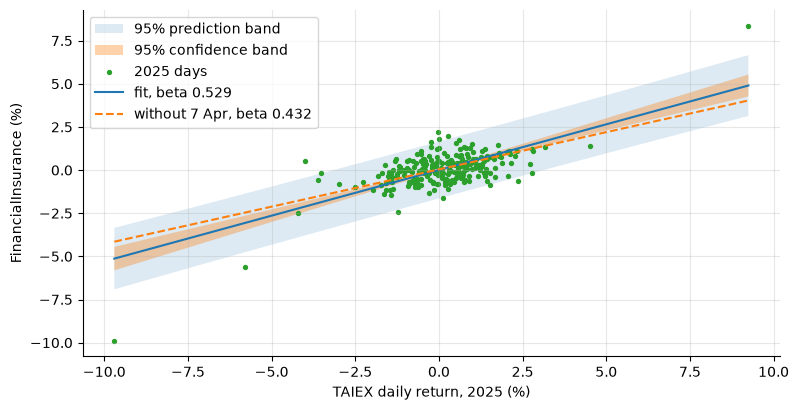

In [7]:
k25 = YRS == "2025"
y25, x25 = X[k25, J["FinancialInsurance"]], M[k25]
f25 = ols(y25, design(x25))
show("2025 returns", int(k25.sum()), "d", "243")
show("beta", f25["b"][1], ".3f", "0.529")
show("classical SE", f25["se_c"][1], ".4f", "0.0350")
show("White SE", f25["se_w"][1], ".3f", "0.106")
show("s_eps (%)", 100 * sqrt(f25["s2"]), ".3f", "0.840")
x0 = np.array([1.0, -0.05])
h0 = x0 @ f25["zi"] @ x0
yhat0, se_fit, se_pred = x0 @ f25["b"], sqrt(f25["s2"] * h0), sqrt(f25["s2"] * (1 + h0))
show("fitted at -5% (%)", 100 * yhat0, ".3f", "-2.642")
show("SE of the fit (points)", 100 * se_fit, ".4f", "0.1865")
show("confidence, low", 100 * (yhat0 - 1.96 * se_fit), ".2f", "-3.01")
show("confidence, high", 100 * (yhat0 + 1.96 * se_fit), ".2f", "-2.28")
show("SE of a prediction (points)", 100 * se_pred, ".3f", "0.860")
show("prediction, low", 100 * (yhat0 - 1.96 * se_pred), ".2f", "-4.33")
show("prediction, high", 100 * (yhat0 + 1.96 * se_pred), ".2f", "-0.96")
show("full-sample half-width at -5% (points)", 100 * 1.96 * sqrt(fin["s2"] * (x0 @ fin["zi"] @ x0)), ".3f", "0.105")

D25 = design(x25)
hat = np.einsum("ij,jk,ik->i", D25, f25["zi"], D25)            # diagonal of Pi
j7 = int(np.argmin(x25))
d25 = [d for d, k in zip(dates, k25) if k]
print("smallest TAIEX return of 2025:", d25[j7], f"{100 * x25[j7]:.4f}%; sum of hat values {hat.sum():.6f}")
show("hat value of 7 April 2025", hat[j7], ".4f", "0.1709")
show("times the average d/T = 2/243", hat[j7] / (2 / len(x25)), ".0f", "21")
keep7 = np.arange(len(x25)) != j7
f25b = ols(y25[keep7], design(x25[keep7]))
show("beta without the day", f25b["b"][1], ".3f", "0.432")
show("shift in classical SEs", (f25["b"][1] - f25b["b"][1]) / f25["se_c"][1], ".1f", "2.8")
show("White SE without the day", f25b["se_w"][1], ".3f", "0.097")
cl = closes.select("date", "TAIEX")
tf = [Fraction(str(v)) for v in cl["TAIEX"].to_list()]
rf = {d: tf[i] / tf[i - 1] - 1 for i, d in enumerate(cl["date"].to_list()) if i > 0 and tf[i] is not None}
assert min(rf, key=rf.get) == "2025-04-07"
show("2025 days with TAIEX <= -5% (Fraction)", sum(1 for d, v in rf.items() if d[:4] == "2025" and v <= Fraction(-5, 100)),
     "d", "2")
show("2025 days with TAIEX <= -5% (guard)", int((x25 <= -0.05 + EPS).sum()), "d", "2")

order = np.argsort(x25)
grid = np.linspace(x25.min(), x25.max(), 60)
Zg = design(grid)
hg = np.einsum("ij,jk,ik->i", Zg, f25["zi"], Zg)
fit_g = Zg @ f25["b"]
fig, ax = plt.subplots()
ax.fill_between(100 * grid, 100 * (fit_g - 1.96 * np.sqrt(f25["s2"] * (1 + hg))),
                100 * (fit_g + 1.96 * np.sqrt(f25["s2"] * (1 + hg))), alpha=0.15, label="95% prediction band")
ax.fill_between(100 * grid, 100 * (fit_g - 1.96 * np.sqrt(f25["s2"] * hg)),
                100 * (fit_g + 1.96 * np.sqrt(f25["s2"] * hg)), alpha=0.35, label="95% confidence band")
ax.scatter(100 * x25[order], 100 * y25[order], s=8, label="2025 days")
ax.plot(100 * grid, 100 * fit_g, label=f"fit, beta {f25['b'][1]:.3f}")
ax.plot(100 * grid, 100 * (design(grid) @ f25b["b"]), "--", label=f"without 7 Apr, beta {f25b['b'][1]:.3f}")
ax.set_xlabel("TAIEX daily return, 2025 (%)"); ax.set_ylabel("FinancialInsurance (%)"); ax.legend(); plt.show()

## Part 4 — White's standard errors

**Example 4.** LM18's experiment 3 recomputed with LM18's own seed: 10,000 five-year paths of iid normal log returns with TR23's $\bar r$ and $s_r$ (divisor $T$), `default_rng([3, 20261011])`, 20 chunks of `standard_normal((500, m))`. The model's value of the sandwich (23.6) is a normal integral, computed by 200-node Gauss–Hermite quadrature. These numbers use TR23 alone, so they do not change on the free plan.

In [8]:
r_tr = np.log1p((tr["price"] / tr["price"].shift(1) - 1).to_numpy()[1:])
years_tr = (date.fromisoformat(tr["date"][-1]) - date.fromisoformat(tr["date"][0])).days / 365.25
m5 = round(5 * len(r_tr) / years_tr)
rbar, s_r = r_tr.mean(), r_tr.std(ddof=0)
show("m", m5, ",", "1,231", kept=True)
rng3 = np.random.default_rng([3, 20261011])                      # LM18's experiment 3, created once
S = np.empty(10_000)
for c0 in range(0, 10_000, 500):
    S[c0:c0 + 500] = (rbar + s_r * rng3.standard_normal((500, m5))).sum(axis=1)
G = np.exp(S)
f18 = ols(G, design(S), lag=0)
batch = [np.cov(G[i:i + 500], S[i:i + 500], ddof=0)[0, 1] / S[i:i + 500].var(ddof=0) for i in range(0, 10_000, 500)]
bse = np.std(batch, ddof=0) / sqrt(20)
mu_s, v_s = m5 * rbar, m5 * s_r**2
nodes, wts = np.polynomial.hermite_e.hermegauss(200)
wts = wts / wts.sum()
sq = mu_s + sqrt(v_s) * nodes
beta_model = np.exp(mu_s + v_s / 2)
eq = np.exp(sq) - beta_model - beta_model * (sq - mu_s)
se_sand = sqrt((wts * (sq - mu_s) ** 2 * eq**2).sum() / (10_000 * v_s**2))
show("beta hat", f18["b"][1], ".4f", "2.1759", kept=True)
show("classical SE", f18["se_c"][1], ".4f", "0.0067", kept=True)
show("White SE", f18["se_w"][1], ".4f", "0.0152", kept=True)
show("LM18's batch SE", bse, ".4f", "0.0113", kept=True)
show("model slope E G", beta_model, ".4f", "2.1584", kept=True)
show("model SE (quadrature)", se_sand, ".4f", "0.0157", kept=True)
show("classical / model (%)", 100 * f18["se_c"][1] / se_sand, ".0f", "43", kept=True)
show("White / model", f18["se_w"][1] / se_sand, ".2f", "0.97", kept=True)
show("batch / model", bse / se_sand, ".2f", "0.72", kept=True)
q1, q2 = np.quantile(S, [1 / 3, 2 / 3], method="inverted_cdf")
for name, g, pr in (("lower", S <= q1, "0.260"), ("middle", (S > q1) & (S <= q2), "0.179"), ("upper", S > q2, "0.378")):
    show(f"residual root mean square, {name} third", sqrt(np.mean(f18["e"][g] ** 2)), ".3f", pr, kept=True)

ratio_w = {nm: FITS[nm]["se_w"][1] / FITS[nm]["se_c"][1] for nm in U28}
show("White / classical, smallest", min(ratio_w.values()), ".2f", "1.19")
show("White / classical, largest", max(ratio_w.values()), ".2f", "1.91")
show("2025 White / classical", f25["se_w"][1] / f25["se_c"][1], ".0f", "3")

f16 = ols(y_fi, design(X[:, J["Semiconductor"]]))
show("LM16's slope", f16["b"][1], ".4f", "0.4591")
show("classical", f16["se_c"][1], ".4f", "0.0099")
show("White", f16["se_w"][1], ".4f", "0.0165")
show("Newey-West (9)", f16["se_n"][1], ".4f", "0.0229")
show("interval, low", f16["b"][1] - 1.96 * f16["se_n"][1], ".3f", "0.414")
show("interval, high", f16["b"][1] + 1.96 * f16["se_n"][1], ".3f", "0.504")
show("s_eps divisor T - 2 (%)", 100 * sqrt(f16["s2"]), ".5f", "0.99626")
show("residual SD divisor T (%)", 100 * f16["e"].std(ddof=0), ".5f", "0.99603")

m: 1,231   [book: 1,231]
beta hat: 2.1759   [book: 2.1759]
classical SE: 0.0067   [book: 0.0067]
White SE: 0.0152   [book: 0.0152]
LM18's batch SE: 0.0113   [book: 0.0113]
model slope E G: 2.1584   [book: 2.1584]
model SE (quadrature): 0.0157   [book: 0.0157]
classical / model (%): 43   [book: 43]
White / model: 0.97   [book: 0.97]
batch / model: 0.72   [book: 0.72]
residual root mean square, lower third: 0.260   [book: 0.260]
residual root mean square, middle third: 0.179   [book: 0.179]
residual root mean square, upper third: 0.378   [book: 0.378]
White / classical, smallest: 1.19   [book: 1.19]
White / classical, largest: 1.91   [book: 1.91]
2025 White / classical: 3   [book: 3]
LM16's slope: 0.4591   [book: 0.4591]
classical: 0.0099   [book: 0.0099]
White: 0.0165   [book: 0.0165]
Newey-West (9): 0.0229   [book: 0.0229]
interval, low: 0.414   [book: 0.414]
interval, high: 0.504   [book: 0.504]
s_eps divisor T - 2 (%): 0.99626   [book: 0.99626]
residual SD divisor T (%): 0.99603   [b

## Part 5 — Overlapping sums and Newey–West

**Exhibit 3 and Example 5.** 20-day sums of log returns, overlapping (every start) and non-overlapping (from the first return, and over the 20 possible starting days). The residuals' autocorrelation is LM19's $\hat\rho_k$: the full-sample mean, divisor $T$ in numerator and denominator.

In [9]:
LX, LM_ = np.log1p(X), np.log1p(M)


def sums(x, m):
    c = np.concatenate([[0.0], np.cumsum(x)])
    return c[m:] - c[:-m]


def rho_hat(x, k):
    c = x - x.mean()
    return (c[k:] @ c[:-k]) / (c @ c)


def overlap(nm, m=20):
    y1 = LX[:, J[nm]]
    fd = ols(y1, design(LM_), lag=0)
    yo, xo = sums(y1, m), sums(LM_, m)
    fo, fo2 = ols(yo, design(xo), lag=m - 1), ols(yo, design(xo), lag=2 * (m - 1))
    nwin = T // m
    fn = ols(y1[:nwin * m].reshape(nwin, m).sum(1), design(LM_[:nwin * m].reshape(nwin, m).sum(1)), lag=0)
    offs = []
    for o in range(m):
        n = (T - o) // m
        offs.append(ols(y1[o:o + n * m].reshape(n, m).sum(1), design(LM_[o:o + n * m].reshape(n, m).sum(1)), lag=0)["b"][1])
    return fd, fo, fo2, fn, offs, nwin, len(yo)


rows = {}
for nm in ("Semiconductor", "FinancialInsurance", "Food"):
    fd, fo, fo2, fn, offs, nwin, nov = overlap(nm)
    rows[nm] = [f"{fd['b'][1]:.3f} ({fd['se_c'][1]:.4f})", f"{fo['b'][1]:.3f}", f"{fo['se_c'][1]:.4f}", f"{fo['se_w'][1]:.4f}",
                f"{fo['se_n'][1]:.4f}", f"{fo2['se_n'][1]:.4f}", f"{fn['b'][1]:.3f} ({fn['se_c'][1]:.4f})",
                f"{min(offs):.3f} to {max(offs):.3f}"]
    if nm == "Semiconductor":
        semi_ov = (fo, nwin, nov)
labels = ["daily beta (classical SE)", "overlapping beta", "SE classical", "SE White", "SE Newey-West 19",
          "SE Newey-West 38", "non-overlapping beta (classical SE)", "over the 20 starting days"]
print(pl.DataFrame({"row": labels, **rows}))
book = {"Semiconductor": ["1.204 (0.0088)", "1.157", "0.0089", "0.0115", "0.0389", "0.0464", "1.106 (0.0406)", "1.106 to 1.189"],
        "FinancialInsurance": ["0.824 (0.0103)", "0.801", "0.0106", "0.0164", "0.0543", "0.0610", "0.867 (0.0509)",
                               "0.707 to 0.889"],
        "Food": ["0.538 (0.0117)", "0.444", "0.0109", "0.0159", "0.0535", "0.0628", "0.518 (0.0515)", "0.387 to 0.518"]}
for nm in book:
    for a, b in zip(rows[nm], book[nm]):
        show(f"{nm}", a, "s", b)
fo, nwin, nov = semi_ov
show("overlapping windows", nov, ",", "4,363")
show("non-overlapping sums", nwin, "d", "219")
show("Newey-West (19) / classical", fo["se_n"][1] / fo["se_c"][1], ".2f", "4.35")
for k, pr in ((1, "0.953"), (10, "0.538"), (20, "0.038")):
    show(f"overlap residual rho_hat_{k}", rho_hat(fo["e"], k), ".3f", pr)

shape: (8, 4)
┌─────────────────────────────────┬────────────────┬────────────────────┬────────────────┐
│ row                             ┆ Semiconductor  ┆ FinancialInsurance ┆ Food           │
│ ---                             ┆ ---            ┆ ---                ┆ ---            │
│ str                             ┆ str            ┆ str                ┆ str            │
╞═════════════════════════════════╪════════════════╪════════════════════╪════════════════╡
│ daily beta (classical SE)       ┆ 1.204 (0.0088) ┆ 0.824 (0.0103)     ┆ 0.538 (0.0117) │
│ overlapping beta                ┆ 1.157          ┆ 0.801              ┆ 0.444          │
│ SE classical                    ┆ 0.0089         ┆ 0.0106             ┆ 0.0109         │
│ SE White                        ┆ 0.0115         ┆ 0.0164             ┆ 0.0159         │
│ SE Newey-West 19                ┆ 0.0389         ┆ 0.0543             ┆ 0.0535         │
│ SE Newey-West 38                ┆ 0.0464         ┆ 0.0610             ┆ 0.

**The iid factors of the Deep Dive.** Under iid days, the products of the error and regressor sums have autocovariance $(m-k)^2\sigma_\varepsilon^2\sigma_x^2$ for $k<m$, so the true variance of the overlapping slope is $(2m^2+1)/(3m)$ times the classical one; Bartlett weights at lag $\ell$ keep $1-k/(\ell+1)$ of each term.

In [10]:
def iid_factor(m, lag=None):
    if lag is None:
        return sqrt((m * m + 2 * sum((m - k) ** 2 for k in range(1, m))) / (m * m))
    return sqrt((m * m + 2 * sum((1 - k / (lag + 1)) * (m - k) ** 2 for k in range(1, min(lag, m - 1) + 1))) / (m * m))


show("true factor", iid_factor(20), ".2f", "3.65", kept=True)
show("Bartlett, lag 19", iid_factor(20, 19), ".2f", "3.17", kept=True)
show("Bartlett, lag 38", iid_factor(20, 38), ".2f", "3.41", kept=True)

true factor: 3.65   [book: 3.65]
Bartlett, lag 19: 3.17   [book: 3.17]
Bartlett, lag 38: 3.41   [book: 3.41]


**Exhibit 4.** The Newey–West standard error of Semiconductor's daily beta against the lag, always with the full-sample bread: the full-sample residuals, then the residuals of one fit per calendar year (2008's 22 returns form their own).

lag 0, full-sample residuals: 0.0129   [book: 0.0129]
lag 0, yearly-fit residuals: 0.0122   [book: 0.0122]
lag 9, full-sample residuals: 0.0185   [book: 0.0185]
lag 9, yearly-fit residuals: 0.0152   [book: 0.0152]
lag 50, full-sample residuals: 0.0275   [book: 0.0275]
lag 50, yearly-fit residuals: 0.0160   [book: 0.0160]
lag 200, full-sample residuals: 0.0390   [book: 0.0390]
lag 200, yearly-fit residuals: 0.0123   [book: 0.0123]


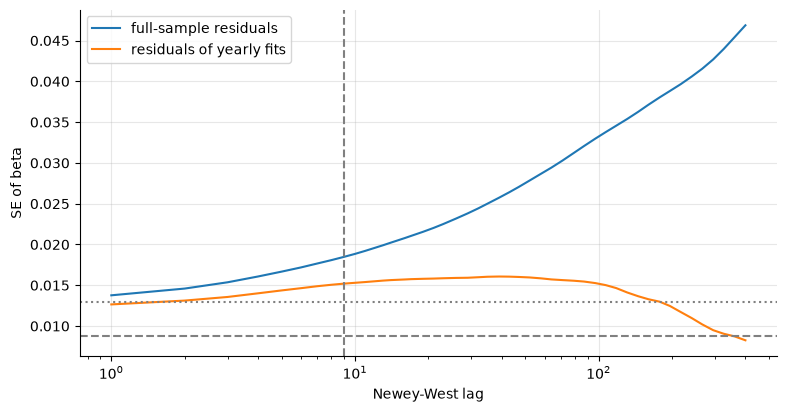

In [11]:
ys = X[:, J["Semiconductor"]]
e_year = np.empty(T)
for yy in sorted(set(YRS)):
    k = YRS == yy
    e_year[k] = ols(ys[k], ZM[k], lag=0)["e"]
gam = {}
for name, e in (("pooled", semi["e"]), ("yearly", e_year)):
    u = ZM * e[:, None]
    gam[name] = [u.T @ u] + [u[k:].T @ u[:-k] for k in range(1, 401)]


def nw_curve(name, lag):
    s = gam[name][0].copy()
    for k in range(1, lag + 1):
        s = s + (1 - k / (lag + 1)) * (gam[name][k] + gam[name][k].T)
    return sqrt((semi["zi"] @ s @ semi["zi"])[1, 1])


for lag, p0, p1 in ((0, "0.0129", "0.0122"), (9, "0.0185", "0.0152"), (50, "0.0275", "0.0160"), (200, "0.0390", "0.0123")):
    show(f"lag {lag}, full-sample residuals", nw_curve("pooled", lag), ".4f", p0)
    show(f"lag {lag}, yearly-fit residuals", nw_curve("yearly", lag), ".4f", p1)
lags = np.unique(np.round(np.geomspace(1, 400, 60)).astype(int))
fig, ax = plt.subplots()
ax.plot(lags, [nw_curve("pooled", int(g)) for g in lags], label="full-sample residuals")
ax.plot(lags, [nw_curve("yearly", int(g)) for g in lags], label="residuals of yearly fits")
ax.axhline(semi["se_c"][1], ls="--", c="grey"); ax.axhline(semi["se_w"][1], ls=":", c="grey"); ax.axvline(9, ls="--", c="grey")
ax.set_xscale("log"); ax.set_xlabel("Newey-West lag"); ax.set_ylabel("SE of beta"); ax.legend(); plt.show()

## Part 6 — The market model, stability and hedging

**(23.8).** The raw intercept on price indices mixes Jensen's alpha with an interest term and a dividend term. With $r_f=2\%$ a year and equal dividend yields, $q_i=q_{\text{mkt}}$, Jensen's alpha is the raw intercept minus $(1-\beta)r_f/A$ plus $(q_i-\beta q_{\text{mkt}})/A$.

In [12]:
b = semi["b"][1]
rf_term, div_term = (1 - b) * 0.02 / A, (q_mkt - b * q_mkt) / A
show("r_f term, added to Jensen's alpha (bp)", -1e4 * rf_term, ".2f", "0.17")
show("dividend term, subtracted (bp)", -1e4 * div_term, ".2f", "0.29")
show("Jensen's alpha (bp)", 1e4 * (semi["b"][0] - rf_term + div_term), ".2f", "1.98")
show("one point of yield (bp a day)", 1e4 * 0.01 / A, ".2f", "0.41")
ci = FITS["CommunicationsInternet"]
show("CommunicationsInternet beta", ci["b"][1], ".3f", "0.507")
show("raw intercept (bp)", 1e4 * ci["b"][0], ".2f", "-0.18")
show("its classical SE (bp)", 1e4 * ci["se_c"][0], ".2f", "0.99")
show("r_f term (bp a day)", 1e4 * (1 - ci["b"][1]) * 0.02 / A, ".2f", "0.40")
show("Jensen-type alpha (bp, one decimal)", 1e4 * (ci["b"][0] - (1 - ci["b"][1]) * 0.02 / A), ".1f", "-0.6")

r_f term, added to Jensen's alpha (bp): 0.17   [book: 0.17]
dividend term, subtracted (bp): 0.29   [book: 0.29]
Jensen's alpha (bp): 1.98   [book: 1.98]
one point of yield (bp a day): 0.41   [book: 0.41]
CommunicationsInternet beta: 0.507   [book: 0.507]
raw intercept (bp): -0.18   [book: -0.18]
its classical SE (bp): 0.99   [book: 0.99]
r_f term (bp a day): 0.40   [book: 0.40]
Jensen-type alpha (bp, one decimal): -0.6   [book: -0.6]


**Exhibit 5.** The 28 betas of the full sample and of the halves, with the change between the halves in standard errors, $z=(\hat\beta_{\text{second}}-\hat\beta_{\text{first}})/\sqrt{\operatorname{SE}_{\text{first}}^2+\operatorname{SE}_{\text{second}}^2}$, from Newey–West errors ($\ell=7$ in each half).

shape: (28, 4)
┌────────────────────────────────┬──────────┬──────────┬────────────┐
│ sector                         ┆ first    ┆ second   ┆ z          │
│ ---                            ┆ ---      ┆ ---      ┆ ---        │
│ str                            ┆ f64      ┆ f64      ┆ f64        │
╞════════════════════════════════╪══════════╪══════════╪════════════╡
│ FinancialInsurance             ┆ 1.155587 ┆ 0.57836  ┆ -13.535309 │
│ TradingConsumersGoods          ┆ 0.856251 ┆ 0.37438  ┆ -11.881799 │
│ Cement                         ┆ 0.981721 ┆ 0.463059 ┆ -10.032516 │
│ Food                           ┆ 0.803901 ┆ 0.339448 ┆ -10.016624 │
│ Textiles                       ┆ 1.00433  ┆ 0.569519 ┆ -8.440903  │
│ BuildingMaterialConstruction   ┆ 1.010713 ┆ 0.505959 ┆ -8.380244  │
│ Rubber                         ┆ 0.864701 ┆ 0.509193 ┆ -7.63978   │
│ Chemical                       ┆ 0.92928  ┆ 0.680896 ┆ -6.605809  │
│ Automobile                     ┆ 1.123614 ┆ 0.74771  ┆ -6.33273   │
│ Com

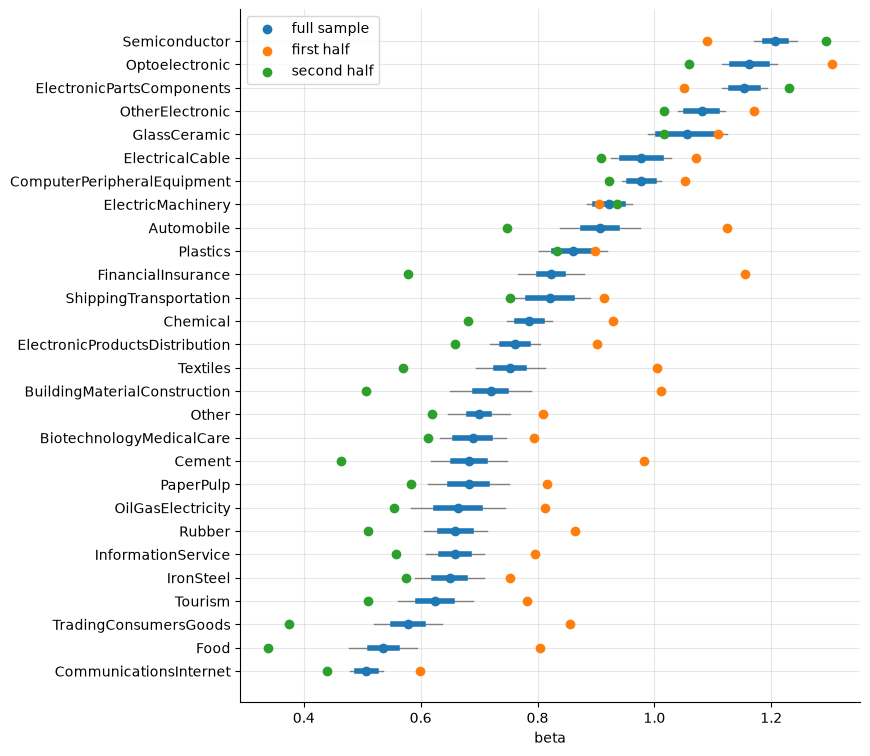

In [13]:
halves = []
for nm in U28:
    a1, a2 = ols(X[:H, J[nm]], ZM[:H]), ols(X[H:, J[nm]], ZM[H:])
    halves.append((nm, a1["b"][1], a2["b"][1], (a2["b"][1] - a1["b"][1]) / sqrt(a1["se_n"][1] ** 2 + a2["se_n"][1] ** 2)))
hv = pl.DataFrame(halves, schema=["sector", "first", "second", "z"], orient="row").sort("z")
print(hv)
show("sectors with |z| > 1.96", sum(1 for h in halves if abs(h[3]) > 1.96 + EPS), "d", "25")
b1v, b2v = np.array([h[1] for h in halves]), np.array([h[2] for h in halves])
show("correlation of the halves' betas", np.corrcoef(b1v, b2v)[0, 1], ".3f", "0.653")
srt = sorted(U28, key=betas.get)
fig, ax = plt.subplots(figsize=(8, 9))
for i, nm in enumerate(srt):
    f_ = FITS[nm]
    ax.plot([f_["b"][1] - 1.96 * f_["se_n"][1], f_["b"][1] + 1.96 * f_["se_n"][1]], [i, i], c="grey", lw=1)
    ax.plot([f_["b"][1] - 1.96 * f_["se_c"][1], f_["b"][1] + 1.96 * f_["se_c"][1]], [i, i], c="C0", lw=4)
ax.scatter([betas[nm] for nm in srt], range(28), c="C0", zorder=3, label="full sample")
ax.scatter([dict((h[0], h[1]) for h in halves)[nm] for nm in srt], range(28), c="C1", zorder=3, label="first half")
ax.scatter([dict((h[0], h[2]) for h in halves)[nm] for nm in srt], range(28), c="C2", zorder=3, label="second half")
ax.set_yticks(range(28), srt); ax.set_xlabel("beta"); ax.legend(); plt.show()

**Exhibit 6.** Rolling 250-return betas ($\Cov/\Var$ with `ddof=0`, equal to the OLS slope) with their classical 95% bands, dated by each window's last day.

windows: 4,133   [book: 4,133]
first window ends 2009-11-30
FinancialInsurance: max 1.377 (2010-02-23), min 0.251 (2026-05-26), last 0.308
Semiconductor: max 1.658 (2020-01-17), min 0.914 (2011-05-18), last 1.168


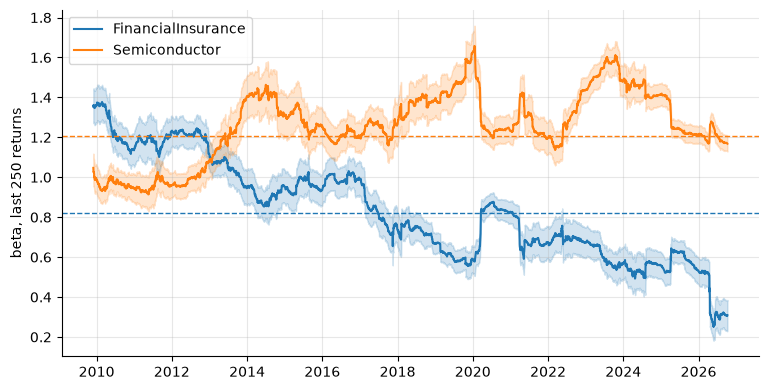

FinancialInsurance max: 1.377   [book: 1.377]
FinancialInsurance min: 0.251   [book: 0.251]
FinancialInsurance last: 0.308   [book: 0.308]
Semiconductor min: 0.914   [book: 0.914]
Semiconductor max: 1.658   [book: 1.658]
Semiconductor last: 1.168   [book: 1.168]


In [14]:
def rolling(y, x, w=250):
    c = lambda v: np.concatenate([[0.0], np.cumsum(v)])
    sy, sx_, syy, sxx, sxy = (c(v)[w:] - c(v)[:-w] for v in (y, x, y * y, x * x, x * y))
    vx, vy, cv = sxx / w - (sx_ / w) ** 2, syy / w - (sy / w) ** 2, sxy / w - (sx_ / w) * (sy / w)
    bb = cv / vx
    return bb, np.sqrt(w * (vy - bb * cv) / (w - 2) / (w * vx))


rd = dates[249:]
show("windows", len(rd), ",", "4,133")
print("first window ends", rd[0])
fig, ax = plt.subplots()
for nm, color in (("FinancialInsurance", "C0"), ("Semiconductor", "C1")):
    bb, se = rolling(X[:, J[nm]], M)
    print(f"{nm}: max {bb.max():.3f} ({rd[int(bb.argmax())]}), min {bb.min():.3f} ({rd[int(bb.argmin())]}), last {bb[-1]:.3f}")
    xd = np.array(rd, dtype="datetime64[D]")
    ax.fill_between(xd, bb - 1.96 * se, bb + 1.96 * se, color=color, alpha=0.2)
    ax.plot(xd, bb, color=color, label=nm)
    ax.axhline(betas[nm], ls="--", color=color, lw=1)
ax.set_ylabel("beta, last 250 returns"); ax.legend(); plt.show()
bf, _ = rolling(X[:, J["FinancialInsurance"]], M)
bs, _ = rolling(X[:, J["Semiconductor"]], M)
show("FinancialInsurance max", bf.max(), ".3f", "1.377")
show("FinancialInsurance min", bf.min(), ".3f", "0.251")
show("FinancialInsurance last", bf[-1], ".3f", "0.308")
show("Semiconductor min", bs.min(), ".3f", "0.914")
show("Semiconductor max", bs.max(), ".3f", "1.658")
show("Semiconductor last", bs[-1], ".3f", "1.168")

**Example 6.** The variance-minimizing hedge ratio is the beta, and the contracts follow from LM8's contract value $200F_t$ NT\$. TX's settlement on 8 October 2026, $F_t=49{,}357$ (the 202610 contract), is the module's printed input (from `data/vol4_series.py`), so the lab needs no futures file. The first half's ratio is judged on the second half: out of sample.

In [15]:
def slope_r2(yy, xx):
    c_ = np.cov(yy, xx, ddof=0)
    return c_[0, 1] / c_[1, 1], c_[0, 1] ** 2 / (c_[0, 0] * c_[1, 1])


hb = {k: slope_r2(y_fi[s], M[s]) for k, s in (("full", slice(None)), ("first", slice(0, H)), ("second", slice(H, None)),
                                             ("last250", slice(T - 250, None)))}
show("full-sample beta", hb["full"][0], ".5f", "0.82338")
show("its R-squared", hb["full"][1], ".4f", "0.5916")
show("last-250 beta", hb["last250"][0], ".5f", "0.30847")
show("its R-squared", hb["last250"][1], ".4f", "0.1989")
F_t = 49_357                                          # printed input: TX23's settlement on 2026-10-08
notional = 100e6 / (200 * F_t)
show("notional contracts", notional, ".2f", "10.13", kept=True)
show("full-beta contracts", hb["full"][0] * notional, ".2f", "8.34")
show("last-250 contracts", hb["last250"][0] * notional, ".2f", "3.12")
show("first-half beta", hb["first"][0], ".4f", "1.1556")
show("second-half beta", hb["second"][0], ".4f", "0.5784")
y2, m2 = y_fi[H:], M[H:]
for name, h, pr in (("first-half beta", hb["first"][0], "0.19"), ("ratio 1", 1.0, "23.09"),
                    ("second half's own beta", hb["second"][0], "49.29")):
    show(f"second-half variance cut by the {name} (%)", 100 * (1 - np.var(y2 - h * m2, ddof=0) / np.var(y2, ddof=0)), ".2f", pr)

full-sample beta: 0.82338   [book: 0.82338]
its R-squared: 0.5916   [book: 0.5916]
last-250 beta: 0.30847   [book: 0.30847]
its R-squared: 0.1989   [book: 0.1989]
notional contracts: 10.13   [book: 10.13]
full-beta contracts: 8.34   [book: 8.34]
last-250 contracts: 3.12   [book: 3.12]
first-half beta: 1.1556   [book: 1.1556]
second-half beta: 0.5784   [book: 0.5784]
second-half variance cut by the first-half beta (%): 0.19   [book: 0.19]
second-half variance cut by the ratio 1 (%): 23.09   [book: 23.09]
second-half variance cut by the second half's own beta (%): 49.29   [book: 49.29]


**Example 7.** LM2's slope of 00631L on 0050 with an error bar, the designed multiple 2, and the extreme calendar years 2015–2025. These use the funds' own files, so they do not change on the free plan.

In [16]:
f2 = ols(R631, design(R50))
show("slope", f2["b"][1], ".4f", "1.8865", kept=True)
show("classical", f2["se_c"][1], ".4f", "0.0081", kept=True)
show("White", f2["se_w"][1], ".4f", "0.0154", kept=True)
show("Newey-West (8)", f2["se_n"][1], ".4f", "0.0211", kept=True)
show("distance to 2 in Newey-West SEs", (2 - f2["b"][1]) / f2["se_n"][1], ".2f", "5.38", kept=True)
show("interval, low", f2["b"][1] - 1.96 * f2["se_n"][1], ".3f", "1.845", kept=True)
show("interval, high", f2["b"][1] + 1.96 * f2["se_n"][1], ".3f", "1.928", kept=True)
yr = np.array([d[:4] for d in etf_dates])
by = {y: ols(R631[yr == y], design(R50[yr == y])) for y in sorted(set(yr)) if "2015" <= y <= "2025"}
lo, hi = min(by, key=lambda y: by[y]["b"][1]), max(by, key=lambda y: by[y]["b"][1])
print("extreme years:", lo, hi)
show("2024 slope", by["2024"]["b"][1], ".3f", "1.717", kept=True)
show("2021 slope", by["2021"]["b"][1], ".3f", "1.984", kept=True)
show("2024 Newey-West (4)", by["2024"]["se_n"][1], ".4f", "0.0759", kept=True)
show("2021 Newey-West (4)", by["2021"]["se_n"][1], ".4f", "0.0776", kept=True)
show("z of the difference", (by["2021"]["b"][1] - by["2024"]["b"][1]) /
     sqrt(by["2021"]["se_n"][1] ** 2 + by["2024"]["se_n"][1] ** 2), ".1f", "2.5", kept=True)

slope: 1.8865   [book: 1.8865]
classical: 0.0081   [book: 0.0081]
White: 0.0154   [book: 0.0154]
Newey-West (8): 0.0211   [book: 0.0211]
distance to 2 in Newey-West SEs: 5.38   [book: 5.38]
interval, low: 1.845   [book: 1.845]
interval, high: 1.928   [book: 1.928]
extreme years: 2024 2021
2024 slope: 1.717   [book: 1.717]
2021 slope: 1.984   [book: 1.984]
2024 Newey-West (4): 0.0759   [book: 0.0759]
2021 Newey-West (4): 0.0776   [book: 0.0776]
z of the difference: 2.5   [book: 2.5]


## Part 7 — Twenty-eight alphas

**Exhibit 7.** The 28 intercept t-stats, classical and Newey–West, and LM21's three corrections with the method always named (statsmodels' default is Holm–Šidák).

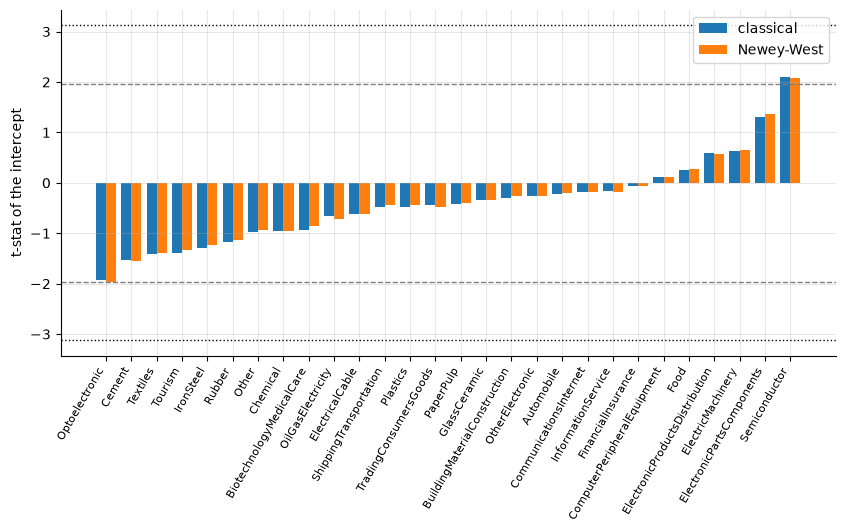

Semiconductor, classical: 2.10   [book: 2.10]
Semiconductor, Newey-West: 2.09   [book: 2.09]
Optoelectronic, classical: -1.94   [book: -1.94]
Optoelectronic, Newey-West: -1.96   [book: -1.96]
Cement, classical: -1.53   [book: -1.53]
Cement, Newey-West: -1.56   [book: -1.56]
Optoelectronic, Newey-West (3 decimals): -1.965   [book: -1.965]
Bonferroni p: 0.00179   [book: 0.00179]
Bonferroni |t|: 3.12   [book: 3.12]
bonferroni: rejections classical 0, Newey-West 0
holm: rejections classical 0, Newey-West 0
fdr_bh: rejections classical 0, Newey-West 0
BH by hand, largest i with p_(i) <= 0.05 i/28: 0
smallest p-value: 0.036   [book: 0.036]
Holm's smallest adjusted p: 1.000   [book: 1.000]
BH's smallest adjusted p: 0.742   [book: 0.742]


In [17]:
order = sorted(U28, key=t_c.get)
fig, ax = plt.subplots(figsize=(10, 4.5))
xs_ = np.arange(28)
ax.bar(xs_ - 0.2, [t_c[k] for k in order], 0.4, label="classical")
ax.bar(xs_ + 0.2, [t_n[k] for k in order], 0.4, label="Newey-West")
zb = stats.norm.isf(0.025 / 28)
for v in (1.96, -1.96):
    ax.axhline(v, ls="--", c="grey", lw=1)
for v in (zb, -zb):
    ax.axhline(v, ls=":", c="k", lw=1)
ax.set_xticks(xs_, order, rotation=60, ha="right", fontsize=8); ax.set_ylabel("t-stat of the intercept"); ax.legend(); plt.show()
for nm, a2, b2 in (("Semiconductor", "2.10", "2.09"), ("Optoelectronic", "-1.94", "-1.96"), ("Cement", "-1.53", "-1.56")):
    show(f"{nm}, classical", t_c[nm], ".2f", a2)
    show(f"{nm}, Newey-West", t_n[nm], ".2f", b2)
show("Optoelectronic, Newey-West (3 decimals)", t_n["Optoelectronic"], ".3f", "-1.965")
show("Bonferroni p", 0.05 / 28, ".5f", "0.00179", kept=True)
show("Bonferroni |t|", zb, ".2f", "3.12", kept=True)
p_c = np.array([two_sided(t_c[k]) for k in U28])
p_n = np.array([two_sided(t_n[k]) for k in U28])
for meth in ("bonferroni", "holm", "fdr_bh"):
    print(f"{meth}: rejections classical {multipletests(p_c, alpha=0.05, method=meth)[0].sum()}, "
          f"Newey-West {multipletests(p_n, alpha=0.05, method=meth)[0].sum()}")
ps = np.sort(p_c)
print("BH by hand, largest i with p_(i) <= 0.05 i/28:", sum(1 for i, p in enumerate(ps, 1) if p <= 0.05 * i / 28))
show("smallest p-value", ps[0], ".3f", "0.036")
show("Holm's smallest adjusted p", multipletests(p_c, method="holm")[1].min(), ".3f", "1.000")
show("BH's smallest adjusted p", multipletests(p_c, method="fdr_bh")[1].min(), ".3f", "0.742")

**Example 8, experiment 1.** The residuals of the 28 market models are correlated, and with one shared regressor so are the intercepts' errors. Draw 100,000 vectors $\mathbf Z\sim\mathcal N_{28}(\mathbf 0,C)$, $C$ the residual correlation matrix, with `default_rng([1, 20261011])` created once, and count $\lvert Z_i\rvert>1.96$ with the guard.

In [18]:
E = np.column_stack([FITS[nm]["e"] for nm in U28])
C = np.corrcoef(E.T)
iu = np.triu_indices(28, 1)
show("residual correlation, min", C[iu].min(), ".3f", "-0.430")
show("residual correlation, max", C[iu].max(), ".3f", "0.462")
show("residual correlation, mean", C[iu].mean(), ".3f", "0.112")
rng1 = np.random.default_rng([1, 20261011])                    # experiment 1, created once
B = 100_000
Z = rng1.standard_normal((B, 28)) @ np.linalg.cholesky(C).T
cnt = (np.abs(Z) > 1.96 + EPS).sum(axis=1)
p_any = (cnt >= 1).mean()
show("count mean", cnt.mean(), ".3f", "1.406")
show("its Monte Carlo SE", cnt.std(ddof=0) / sqrt(B), ".3f", "0.005")
show("count SD", cnt.std(ddof=0), ".3f", "1.458")
show("independent SD", sqrt(28 * 0.05 * 0.95), ".3f", "1.153", kept=True)
show("Pr(at least one)", p_any, ".3f", "0.696")
show("its binomial SE", sqrt(p_any * (1 - p_any) / B), ".4f", "0.0015")
show("independent Pr(at least one)", 1 - 0.95**28, ".4f", "0.7622", kept=True)
show("Pr(three or more)", (cnt >= 3).mean(), ".3f", "0.178")
show("independent Pr(three or more)", stats.binom.sf(2, 28, 0.05), ".3f", "0.163", kept=True)

residual correlation, min: -0.430   [book: -0.430]
residual correlation, max: 0.462   [book: 0.462]
residual correlation, mean: 0.112   [book: 0.112]
count mean: 1.406   [book: 1.406]
its Monte Carlo SE: 0.005   [book: 0.005]
count SD: 1.458   [book: 1.458]
independent SD: 1.153   [book: 1.153]
Pr(at least one): 0.696   [book: 0.696]
its binomial SE: 0.0015   [book: 0.0015]
independent Pr(at least one): 0.7622   [book: 0.7622]
Pr(three or more): 0.178   [book: 0.178]
independent Pr(three or more): 0.163   [book: 0.163]


## Part 8 — A factor named in advance

**Exhibit 8 and Example 9.** The constructed factor $R_{\text{el},t}-R_{\text{mkt},t}$; the raw pair (TAIEX, Electronic) gives the same fit; collinearity measured by the variance inflation factor (23.9). Electronic contains Semiconductor and the other electronics sectors, so their loadings are partly mechanical.

In [19]:
rho_me, rho_mf = np.corrcoef(M, EL)[0, 1], np.corrcoef(M, FX)[0, 1]
show("corr(TAIEX, Electronic)", rho_me, ".4f", "0.9696")
show("VIF, raw pair", 1 / (1 - rho_me**2), ".1f", "16.7")
show("condition number, raw pair", (1 + rho_me) / (1 - rho_me), ".0f", "65")
show("corr(TAIEX, factor)", rho_mf, ".3f", "0.365")
show("VIF, factor pair", 1 / (1 - rho_mf**2), ".2f", "1.15")
show("condition number, factor pair", (1 + rho_mf) / (1 - rho_mf), ".2f", "2.15")
Z2 = design(M, FX)
TWO = {nm: ols(X[:, J[nm]], Z2) for nm in U28}
tab = []
for nm in ("ElectronicPartsComponents", "ComputerPeripheralEquipment", "Semiconductor", "CommunicationsInternet",
           "FinancialInsurance", "Plastics"):
    t2f = TWO[nm]
    tab.append((nm, f"{betas[nm]:.3f}", f"{FITS[nm]['r2']:.4f}", f"{t2f['b'][1]:.3f} ({t2f['se_n'][1]:.3f})",
                f"{t2f['b'][2]:+.3f} ({t2f['se_n'][2]:.3f})", f"{t2f['r2']:.4f}"))
print(pl.DataFrame(tab, schema=["sector", "beta", "R2", "market (NW SE)", "electronics (NW SE)", "R2 two-factor"],
                   orient="row"))
show("Semiconductor row", " | ".join(tab[2][1:]), "s", "1.207 | 0.8112 | 1.037 (0.009) | +1.552 (0.033) | 0.9163")
show("FinancialInsurance row", " | ".join(tab[4][1:]), "s", "0.823 | 0.5916 | 0.997 (0.022) | -1.580 (0.053) | 0.7624")
raw = ols(X[:, J["Semiconductor"]], design(M, EL))
assert np.abs(raw["e"] - TWO["Semiconductor"]["e"]).max() < 1e-12
show("raw pair: TAIEX coefficient", raw["b"][1], ".3f", "-0.515")
show("raw pair: Electronic coefficient", raw["b"][2], "+.3f", "+1.552")
show("raw TAIEX classical SE", raw["se_c"][1], ".3f", "0.024")
show("factor pair market classical SE", TWO["Semiconductor"]["se_c"][1], ".3f", "0.006")
t_el_c = {nm: TWO[nm]["b"][2] / TWO[nm]["se_c"][2] for nm in U28}
t_el_n = {nm: TWO[nm]["b"][2] / TWO[nm]["se_n"][2] for nm in U28}
show("loadings beyond 1.96, classical", sum(abs(v) > 1.96 + EPS for v in t_el_c.values()), "d", "27")
show("loadings beyond 1.96, Newey-West", sum(abs(v) > 1.96 + EPS for v in t_el_n.values()), "d", "27")
show("CommunicationsInternet, classical", t_el_c["CommunicationsInternet"], ".2f", "-1.05")
show("CommunicationsInternet, Newey-West", t_el_n["CommunicationsInternet"], ".2f", "-0.68")
L1 = np.array([ols(X[:H, J[nm]], Z2[:H])["b"][2] for nm in U28])
L2 = np.array([ols(X[H:, J[nm]], Z2[H:])["b"][2] for nm in U28])
show("cosine of the halves' loadings", L1 @ L2 / (np.linalg.norm(L1) * np.linalg.norm(L2)), ".3f", "0.807")

corr(TAIEX, Electronic): 0.9696   [book: 0.9696]
VIF, raw pair: 16.7   [book: 16.7]
condition number, raw pair: 65   [book: 65]
corr(TAIEX, factor): 0.365   [book: 0.365]
VIF, factor pair: 1.15   [book: 1.15]
condition number, factor pair: 2.15   [book: 2.15]
shape: (6, 6)
┌──────────────────────────┬───────┬────────┬────────────────┬─────────────────────┬───────────────┐
│ sector                   ┆ beta  ┆ R2     ┆ market (NW SE) ┆ electronics (NW SE) ┆ R2 two-factor │
│ ---                      ┆ ---   ┆ ---    ┆ ---            ┆ ---                 ┆ ---           │
│ str                      ┆ str   ┆ str    ┆ str            ┆ str                 ┆ str           │
╞══════════════════════════╪═══════╪════════╪════════════════╪═════════════════════╪═══════════════╡
│ ElectronicPartsComponent ┆ 1.154 ┆ 0.6842 ┆ 1.105 (0.019)  ┆ +0.452 (0.058)      ┆ 0.6924        │
│ s                        ┆       ┆        ┆                ┆                     ┆               │
│ ComputerPeriphera

## Part 9 — Practice problems

**Problem 8.** In a simple regression $h_t=\tfrac1T+(x_t-\bar x)^2/(Ts_x^2)$; the hat values are the diagonal of $\Pi$ and sum to 2. From the printed 2025 inputs, then from all 243 hat values.

In [20]:
show("P8 from the printed inputs", 1 / 243 + (-9.6997 - 0.1062) ** 2 / (243 * 1.5405**2), ".4f", "0.1709", kept=True)
show("P8 TAIEX mean 2025 (%)", 100 * x25.mean(), ".4f", "0.1062")
show("P8 s_x 2025 (%)", 100 * x25.std(ddof=0), ".4f", "1.5405")
show("P8 x_t (%)", 100 * x25[j7], ".4f", "-9.6997")
n25 = len(x25)                                        # 243 with every close repaired
formula = 1 / n25 + (x25 - x25.mean()) ** 2 / (n25 * x25.var(ddof=0))
assert np.allclose(formula, hat, rtol=0, atol=1e-12)
print(f"sum of the {n25} hat values: {hat.sum():.12f}; largest three: {np.sort(hat)[-3:].round(4)}")

P8 from the printed inputs: 0.1709   [book: 0.1709]
P8 TAIEX mean 2025 (%): 0.1062   [book: 0.1062]
P8 s_x 2025 (%): 1.5405   [book: 1.5405]
P8 x_t (%): -9.6997   [book: -9.6997]
sum of the 243 hat values: 2.000000000000; largest three: [0.0643 0.149  0.1709]


**Problem 11** is the statsmodels cell of Part 2. **Problem 12**: the 28 classical t-stats, their p-values and the three corrections with `method` passed, then experiment 1.

In [21]:
show("P12 smallest t-stat (Optoelectronic)", t_c["Optoelectronic"], ".3f", "-1.935")
show("P12 largest t-stat (Semiconductor)", t_c["Semiconductor"], ".3f", "2.097")
for meth in ("bonferroni", "holm", "fdr_bh"):
    show(f"P12 rejections, {meth}", int(multipletests(p_c, alpha=0.05, method=meth)[0].sum()), "d", "0")
show("P12 Pr(at least one)", p_any, ".3f", "0.696")

P12 smallest t-stat (Optoelectronic): -1.935   [book: -1.935]
P12 largest t-stat (Semiconductor): 2.097   [book: 2.097]
P12 rejections, bonferroni: 0   [book: 0]
P12 rejections, holm: 0   [book: 0]
P12 rejections, fdr_bh: 0   [book: 0]
P12 Pr(at least one): 0.696   [book: 0.696]


### Extension: a walk-forward hedge

Fix one rule in advance and judge it out of sample. At the end of each calendar month from December 2009, estimate FinancialInsurance's beta on the trailing 250 returns, hedge the next month's returns with it, and compare the hedged variance over all those next months with the notional hedge's (ratio 1) and with no hedge. Which rule wins, and in which years does the trailing beta fail? Trying many such rules and keeping the best is the data snooping that LM34 treats; one rule fixed in advance avoids it.

In [22]:
months = np.array([d[:7] for d in dates])
ends = [i for i in range(249, T - 1) if months[i] != months[i + 1]]   # last day of each month with 250 returns behind it
res = {"trailing beta": [], "ratio 1": [], "no hedge": []}
for i in ends:
    w = slice(i - 249, i + 1)
    bb = np.cov(y_fi[w], M[w], ddof=0)[0, 1] / M[w].var(ddof=0)
    nxt = np.flatnonzero(months == months[i + 1])
    res["trailing beta"].append(y_fi[nxt] - bb * M[nxt])
    res["ratio 1"].append(y_fi[nxt] - M[nxt])
    res["no hedge"].append(y_fi[nxt])
var = {k: np.var(np.concatenate(v), ddof=0) for k, v in res.items()}
print(f"{len(ends)} monthly re-estimations; out-of-sample variance relative to no hedge:")
for k in ("trailing beta", "ratio 1"):
    print(f"   {k}: {var[k] / var['no hedge']:.3f}")
# your code: the same comparison year by year, and a window of 60 returns instead of 250

203 monthly re-estimations; out-of-sample variance relative to no hedge:
   trailing beta: 0.370
   ratio 1: 0.496
